# 02 — Baseline y umbral de negocio

Dos objetivos:

1. Establecer el **piso de rendimiento**. Sin un baseline, un PR-AUC de 0,49 no
   se puede interpretar: puede ser excelente o mediocre.
2. Calibrar el **umbral de decisión** con el caso de negocio. El 0,5 por defecto
   casi nunca es la respuesta correcta cuando el costo de un falso positivo y el
   de un falso negativo son distintos.

In [1]:
# Permite importar `src` ejecutando el notebook desde `notebooks/`.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

from src.config import load_config

config = load_config()
print(f"Proyecto: {config.project.name}")
print(f"Raíz:     {PROJECT_ROOT}")


Proyecto: bank-term-deposit-mlops
Raíz:     C:\Users\gjaim\OneDrive - The University of Melbourne\Documents\MLOPS 2026\Project\bank-term-deposit-mlops


In [2]:
from src.data.split import build_splits

splits = build_splits()
print("Tamaños:", splits.sizes())
print("Tasa de positivos:", {k: f"{v:.4f}" for k, v in splits.positive_rates().items()})

Validación: 12 filas duplicadas


Tamaños: {'train': 24712, 'valid': 8238, 'test': 8238}
Tasa de positivos: {'train': '0.1127', 'valid': '0.1126', 'test': '0.1126'}


La tasa de positivos es prácticamente idéntica en los tres splits:
la partición estratificada funcionó. Sin eso, las métricas entre splits no
serían comparables.

## 1. Los baselines

Cuatro niveles, de lo trivial a lo razonable.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from src.features.preprocess import build_model_pipeline
from src.models.evaluate import classification_metrics

baselines = {
    "1. Siempre 'no'": DummyClassifier(strategy="most_frequent"),
    "2. Aleatorio estratificado": DummyClassifier(strategy="stratified", random_state=42),
    "3. Regresión logística": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "4. Árbol de decisión (prof. 5)": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=42
    ),
}

rows = {}
probabilities = {}
for name, estimator in baselines.items():
    model = build_model_pipeline(estimator)
    model.fit(splits.x_train, splits.y_train)
    proba = model.predict_proba(splits.x_valid)[:, 1]
    probabilities[name] = proba

    metrics = classification_metrics(splits.y_valid, proba, threshold=0.5)
    rows[name] = {
        "PR-AUC": metrics["pr_auc"],
        "ROC-AUC": metrics["roc_auc"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1": metrics["f1"],
    }

baseline_table = pd.DataFrame(rows).T.round(4)
display(baseline_table)

print(f"\nPR-AUC de un modelo sin información = tasa base = {splits.y_valid.mean():.4f}")

,PR-AUC,ROC-AUC,Precision,Recall,F1
1. Siempre 'no',0.1126,0.5000,0.0000,0.0000,0.0000
2. Aleatorio estratificado,0.1129,0.5014,0.1153,0.1131,0.1142
3. Regresión logística,0.4417,0.7971,0.3500,0.6250,0.4487
4. Árbol de decisión (prof. 5),0.4087,0.7825,0.3760,0.5916,0.4598



PR-AUC de un modelo sin información = tasa base = 0.1126


### Lo que dice esta tabla

* **"Siempre no"** tiene un accuracy del 89% (no se muestra, por inútil) y un
  recall de 0: no encuentra un solo suscriptor. Es el recordatorio permanente de
  por qué no se optimiza accuracy.
* **La regresión logística** ya supera con holgura el piso de 0,113. Ese es el
  número a batir: cualquier modelo complejo tiene que justificar su complejidad
  contra él.
* El **ROC-AUC** de la logística ronda 0,79 mientras su PR-AUC ronda 0,42. La
  brecha entre ambos es la firma típica del desbalance: el ROC se ve bien porque
  acertar negativos es fácil.

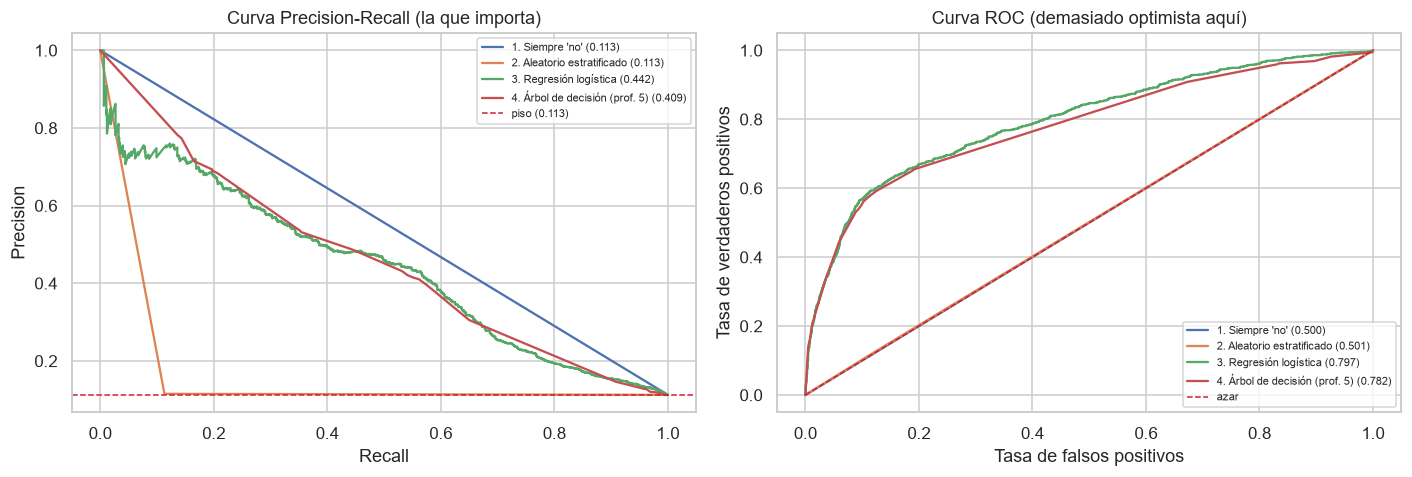

In [4]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, proba in probabilities.items():
    precision, recall, _ = precision_recall_curve(splits.y_valid, proba)
    axes[0].plot(recall, precision, label=f"{name} ({baseline_table.loc[name, 'PR-AUC']:.3f})")

    fpr, tpr, _ = roc_curve(splits.y_valid, proba)
    axes[1].plot(fpr, tpr, label=f"{name} ({baseline_table.loc[name, 'ROC-AUC']:.3f})")

axes[0].axhline(splits.y_valid.mean(), color="#cf222e", linestyle="--", linewidth=1,
                label=f"piso ({splits.y_valid.mean():.3f})")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Curva Precision-Recall (la que importa)")
axes[0].legend(fontsize=7, loc="upper right")

axes[1].plot([0, 1], [0, 1], color="#cf222e", linestyle="--", linewidth=1, label="azar")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Curva ROC (demasiado optimista aquí)")
axes[1].legend(fontsize=7, loc="lower right")

plt.tight_layout()
plt.show()

## 2. El umbral de decisión es una decisión de negocio

El modelo devuelve una probabilidad. Convertirla en "llamar / no llamar" exige
un umbral, y ese umbral depende de la economía del problema, no del modelo.

Supuestos en `configs/config.yaml`:

* costo por llamada: **$8**
* beneficio por suscripción: **$80**

La asimetría es de 10 a 1: vale la pena hacer diez llamadas fallidas para
conseguir una suscripción. En teoría, entonces, el umbral de equilibrio sería
`costo / beneficio = 8 / 80 = 0,10`, muy por debajo del 0,5 por defecto.

Veremos que el óptimo empírico **no** cae en 0,10, y el motivo es informativo.

Mejor baseline: 3. Regresión logística



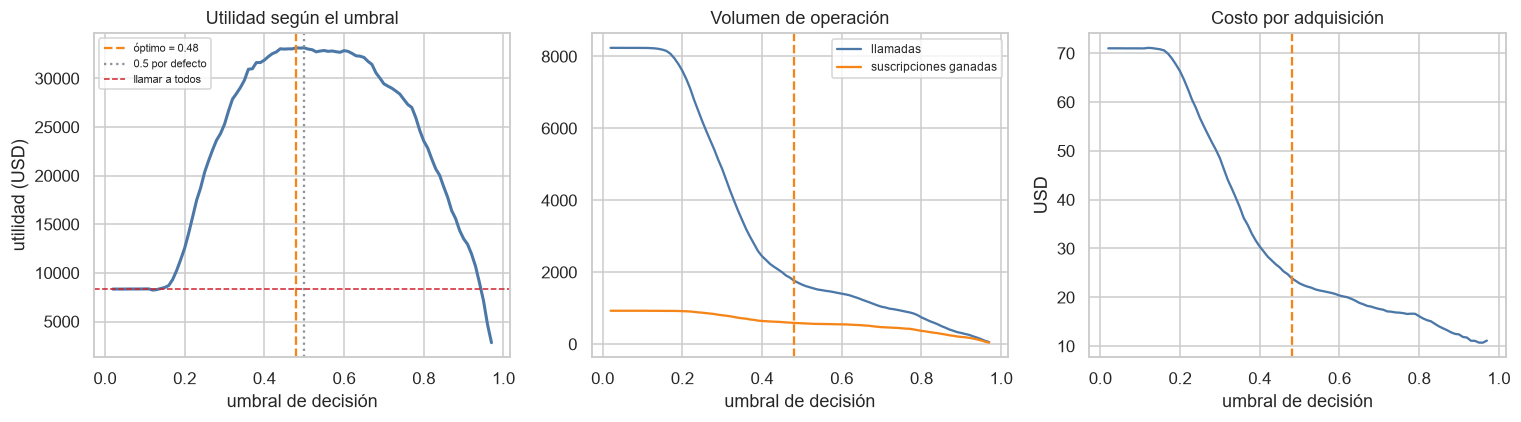

Umbral óptimo:            0.48
Utilidad en ese umbral:   $33,144
Utilidad con umbral 0.5:  $33,144
Utilidad llamando a todos: $8,336


In [5]:
from src.models.evaluate import business_metrics, find_optimal_threshold

best_model_name = baseline_table["PR-AUC"].idxmax()
best_proba = probabilities[best_model_name]
print(f"Mejor baseline: {best_model_name}\n")

grid = np.arange(0.02, 0.98, 0.01)
curve = pd.DataFrame(
    [
        {"umbral": t, **business_metrics(splits.y_valid, best_proba, threshold=float(t))}
        for t in grid
    ]
)

optimal_threshold, optimal_profit = find_optimal_threshold(splits.y_valid, best_proba, grid=grid)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(curve["umbral"], curve["profit_usd"], color="#4c78a8", linewidth=2)
axes[0].axvline(optimal_threshold, color="#f58518", linestyle="--",
                label=f"óptimo = {optimal_threshold:.2f}")
axes[0].axvline(0.5, color="#8b949e", linestyle=":", label="0.5 por defecto")
axes[0].axhline(curve["profit_call_everyone_usd"].iloc[0], color="#cf222e", linestyle="--",
                linewidth=1, label="llamar a todos")
axes[0].set_xlabel("umbral de decisión")
axes[0].set_ylabel("utilidad (USD)")
axes[0].set_title("Utilidad según el umbral")
axes[0].legend(fontsize=7)

axes[1].plot(curve["umbral"], curve["calls_made"], label="llamadas", color="#4c78a8")
axes[1].plot(curve["umbral"], curve["subscriptions_won"], label="suscripciones ganadas",
             color="#f58518")
axes[1].axvline(optimal_threshold, color="#f58518", linestyle="--")
axes[1].set_xlabel("umbral de decisión")
axes[1].set_title("Volumen de operación")
axes[1].legend(fontsize=8)

finite_cpa = curve[np.isfinite(curve["cost_per_acquisition_usd"])]
axes[2].plot(finite_cpa["umbral"], finite_cpa["cost_per_acquisition_usd"], color="#4c78a8")
axes[2].axvline(optimal_threshold, color="#f58518", linestyle="--")
axes[2].set_xlabel("umbral de decisión")
axes[2].set_ylabel("USD")
axes[2].set_title("Costo por adquisición")

plt.tight_layout()
plt.show()

print(f"Umbral óptimo:            {optimal_threshold:.2f}")
print(f"Utilidad en ese umbral:   ${optimal_profit:,.0f}")
print(f"Utilidad con umbral 0.5:  ${business_metrics(splits.y_valid, best_proba, threshold=0.5)['profit_usd']:,.0f}")
print(f"Utilidad llamando a todos: ${curve['profit_call_everyone_usd'].iloc[0]:,.0f}")

### Dos lecturas, una esperada y una que no

**Lo esperado:** la curva de utilidad es plana en una zona amplia y se derrumba
en los extremos. Con umbral muy bajo se llama a todo el mundo y el costo se come
la ganancia; con umbral muy alto se dejan suscripciones sobre la mesa. Y
**llamar a todos da utilidad positiva** con estos supuestos: el banco no está
perdiendo dinero hoy. El valor del modelo no es evitar una pérdida, es
**liberar capacidad del call center** — casi las mismas suscripciones con una
fracción de las llamadas.

**Lo que no esperábamos:** el umbral óptimo quedó cerca de 0,5, no en el 0,10
que predice la economía del problema. Eso **no** significa que el cálculo de
negocio esté mal: significa que **los scores del modelo no son probabilidades
calibradas**.

La causa es `class_weight="balanced"` (y su equivalente `scale_pos_weight` en
XGBoost). Esos parámetros reponderan la clase minoritaria para que el modelo la
aprenda, y como efecto secundario **inflan las probabilidades predichas** muy
por encima de la frecuencia real del 11%. Un score de 0,45 de este modelo no
quiere decir "45% de probabilidad de suscribir".

Consecuencias prácticas, que se arrastran al resto del proyecto:

1. El umbral **hay que buscarlo empíricamente** sobre datos retenidos, que es
   justo lo que hace `find_optimal_threshold`. Derivarlo de la fórmula
   `costo/beneficio` daría un valor equivocado.
2. Los scores sirven para **ordenar** clientes, no como estimaciones absolutas
   de riesgo. Por eso la métrica que se le reporta al negocio es el **lift sobre
   el top-k**, que solo depende del orden.
3. Queda anotado como limitación en `models/model_card.md`: una calibración
   isotónica o de Platt sería el siguiente paso natural si alguien necesitara
   leer los scores como probabilidades.

## 3. La métrica que el negocio entiende: lift sobre el top-k

El call center no decide con un umbral: tiene una capacidad fija. Si solo
alcanza a llamar al 20% de la base, la pregunta es **cuántos suscriptores
captura ese 20%** si se ordena por score en vez de al azar.

,capacidad,llamadas,tasa de conversión,lift,recall capturado
0,top 5%,412,0.5995,5.3220,0.2662
1,top 10%,824,0.4806,4.2662,0.4267
2,top 15%,1236,0.4256,3.7778,0.5668
3,top 20%,1648,0.3513,3.1189,0.6239
4,top 30%,2471,0.2614,2.3208,0.6961
5,top 50%,4119,0.1848,1.6401,0.8200


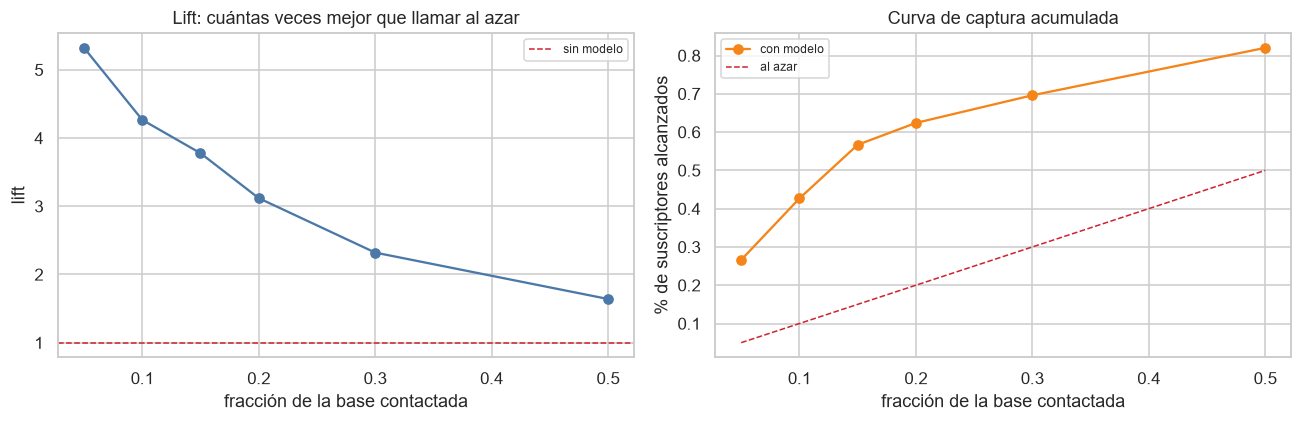

In [6]:
from src.models.evaluate import lift_at_k

fractions = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]
lift_rows = []
for fraction in fractions:
    result = lift_at_k(splits.y_valid, best_proba, k_fraction=fraction)
    key = int(fraction * 100)
    lift_rows.append(
        {
            "capacidad": f"top {key}%",
            "llamadas": result[f"top{key}_calls"],
            "tasa de conversión": result[f"top{key}_conversion_rate"],
            "lift": result[f"top{key}_lift"],
            "recall capturado": result[f"top{key}_recall"],
        }
    )

lift_table = pd.DataFrame(lift_rows)
display(lift_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fractions, lift_table["lift"], marker="o", color="#4c78a8")
axes[0].axhline(1, color="#cf222e", linestyle="--", linewidth=1, label="sin modelo")
axes[0].set_xlabel("fracción de la base contactada")
axes[0].set_ylabel("lift")
axes[0].set_title("Lift: cuántas veces mejor que llamar al azar")
axes[0].legend(fontsize=8)

axes[1].plot(fractions, lift_table["recall capturado"], marker="o", color="#f58518",
             label="con modelo")
axes[1].plot(fractions, fractions, color="#cf222e", linestyle="--", linewidth=1,
             label="al azar")
axes[1].set_xlabel("fracción de la base contactada")
axes[1].set_ylabel("% de suscriptores alcanzados")
axes[1].set_title("Curva de captura acumulada")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Así se explica el modelo a un gerente de call center.** La
columna "recall capturado" de la tabla responde la única pregunta que importa
operativamente: *con la capacidad que tengo, ¿a qué porcentaje de los
suscriptores llego?* Llamar al azar al 20% de la base alcanza al 20% de los
suscriptores (la diagonal roja del gráfico); ordenando por score se alcanza una
fracción bastante mayor, y esa brecha entre las dos curvas **es** el valor del
modelo.

Esta métrica tiene además la virtud de ser inmune al problema de calibración:
solo depende del **orden** de los scores, no de su valor absoluto.

## 4. ¿Vale la pena un modelo más complejo?

In [7]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos_weight = (splits.y_train == 0).sum() / (splits.y_train == 1).sum()

advanced = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=20,
        class_weight="balanced", n_jobs=-1, random_state=42,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=pos_weight, eval_metric="aucpr",
        tree_method="hist", n_jobs=-1, random_state=42,
    ),
}

for name, estimator in advanced.items():
    model = build_model_pipeline(estimator)
    model.fit(splits.x_train, splits.y_train)
    proba = model.predict_proba(splits.x_valid)[:, 1]
    probabilities[name] = proba
    metrics = classification_metrics(splits.y_valid, proba, threshold=optimal_threshold)
    baseline_table.loc[name] = {
        "PR-AUC": metrics["pr_auc"], "ROC-AUC": metrics["roc_auc"],
        "Precision": metrics["precision"], "Recall": metrics["recall"], "F1": metrics["f1"],
    }

comparison = baseline_table.sort_values("PR-AUC", ascending=False).round(4)
display(comparison)

uplift = comparison["PR-AUC"].iloc[0] / baseline_table.loc["3. Regresión logística", "PR-AUC"] - 1
print(f"\nMejora del mejor modelo sobre la regresión logística: {uplift:+.1%}")

,PR-AUC,ROC-AUC,Precision,Recall,F1
Random Forest,0.4655,0.8056,0.3715,0.6218,0.4651
XGBoost,0.4600,0.7977,0.3619,0.6325,0.4604
3. Regresión logística,0.4417,0.7971,0.3500,0.6250,0.4487
4. Árbol de decisión (prof. 5),0.4087,0.7825,0.3760,0.5916,0.4598
2. Aleatorio estratificado,0.1129,0.5014,0.1153,0.1131,0.1142
1. Siempre 'no',0.1126,0.5000,0.0000,0.0000,0.0000



Mejora del mejor modelo sobre la regresión logística: +5.4%


**Veredicto.** Los modelos de árbol le ganan a la regresión
logística, pero por un margen **de un dígito bajo en PR-AUC** (ver el número
impreso arriba), no por órdenes de magnitud.

Esto es información útil, no una decepción. Dice que la señal de este dataset
es en buena medida lineal, y que **la mayor parte del valor del proyecto no está
en el algoritmo**: está en descartar `duration`, en descomponer `pdays`, en
elegir PR-AUC como métrica y en calibrar el umbral contra la economía del
problema. Un equipo que salte directo a XGBoost sin hacer ese trabajo obtiene un
modelo peor, por muchos trials de Optuna que corra.

Se elige XGBoost como candidato a optimizar porque además de rendir algo mejor
entrena rápido, lo que hace viable una búsqueda de 20 trials con Optuna.

**Siguiente paso:** `03_experiments.ipynb` revisa los experimentos registrados
en MLflow, la búsqueda de hiperparámetros y la evaluación final.